# 05 - Decision tree classification (target: Halliwell acclaim >= 2 stars)

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
def show(f, w=900): display(Image(filename=str(ROOT / 'outputs' / 'plots' / f), width=w))

In [2]:
from src.classification import decision_tree
s = decision_tree.run()
s['test_metrics']

2026-11-21 13:04:31,001 | decision_tree | INFO | PHASE 8a - decision tree started


2026-11-21 13:05:11,084 | decision_tree | INFO | PHASE 8a complete: {'final_params': {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 40, 'ccp_alpha': 0.001215}, 'test_metrics': {'accuracy': 0.6533523537803139, 'balanced_accuracy': 0.6702122716035614, 'precision': 0.4766081871345029, 'recall': 0.7180616740088106, 'f1': 0.5729349736379613, 'roc_auc': 0.7389821372144464, 'train_accuracy': 0.6847619047619048, 'leaves': 26, 'depth': 6, 'fit_time_s': 0.027669399976730347, 'predict_time_s': 0.01084959995932877, 'cv_accuracy_mean': 0.6390476190476191, 'cv_accuracy_std': 0.035012145608860554, 'baseline_majority_accuracy': 0.6761768901569187}}


{'accuracy': 0.6533523537803139,
 'balanced_accuracy': 0.6702122716035614,
 'precision': 0.4766081871345029,
 'recall': 0.7180616740088106,
 'f1': 0.5729349736379613,
 'roc_auc': 0.7389821372144464,
 'train_accuracy': 0.6847619047619048,
 'leaves': 26,
 'depth': 6,
 'fit_time_s': 0.027669399976730347,
 'predict_time_s': 0.01084959995932877,
 'cv_accuracy_mean': 0.6390476190476191,
 'cv_accuracy_std': 0.035012145608860554,
 'baseline_majority_accuracy': 0.6761768901569187}

In [3]:
pd.read_csv('outputs/decision_tree/root_split_measures.csv').head(12)

,attribute,info_gain,ig_threshold,gain_ratio,split_info,gini_reduction,gini_threshold,rank_info_gain,rank_gain_ratio,rank_gini_reduction
0,year,0.048622,1966.0,0.052785,0.921127,0.027478,1966.0,1,3,1
1,cast_size,0.032770,7.5,0.035348,0.927079,0.020343,7.5,2,7,2
2,color_type_color,0.031477,0.5,0.031522,0.998554,0.019009,0.5,3,8,3
3,director_n_films,0.028587,8.5,0.029767,0.960362,0.017282,12.5,4,9,4
4,color_type_bw,0.027025,0.5,0.027393,0.986579,0.016486,0.5,5,11,5
5,producer_status_referenced,0.020324,0.5,0.021597,0.941091,0.012557,0.5,6,12,6
6,producer_status_unknown,0.011343,0.5,0.020541,0.552191,0.006291,0.5,7,13,7
7,n_producers,0.010923,0.5,0.017876,0.611031,0.006147,0.5,8,14,8
8,has_book_source,0.009060,0.5,0.012130,0.746909,0.005686,0.5,9,17,9
9,director_country_grp_Germany,0.006253,0.5,0.028131,0.222285,0.004099,0.5,10,10,10


In [4]:
print(open('outputs/decision_tree/classification_report.txt').read())

                      precision    recall  f1-score   support

not acclaimed (0-1*)      0.822     0.622     0.708       474
     acclaimed (2+*)      0.477     0.718     0.573       227

            accuracy                          0.653       701
           macro avg      0.649     0.670     0.641       701
        weighted avg      0.710     0.653     0.664       701



In [5]:
pd.read_csv('outputs/decision_tree/if_then_rules.csv').head(12)

,rule,predicted_class,training_positive_rate,rule_accuracy_on_train,samples,conditions
0,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films > 9.50 AND cast_size > 9....,1,0.800000,0.800000,110,6
1,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films > 9.50 AND cast_size <= 9...,1,0.638554,0.638554,83,6
2,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films > 9.50 AND cast_size > 9....,1,0.584906,0.584906,53,6
3,IF year <= 1967.50 AND cast_size <= 7.50 AND n_producers > 0.50 AND year <= 1939.50 AN...,1,0.577982,0.577982,109,5
4,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films > 9.50 AND cast_size <= 9...,1,0.500000,0.500000,58,6
5,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films > 9.50 AND cast_size > 9....,1,0.487805,0.487805,41,5
6,IF year <= 1967.50 AND cast_size <= 7.50 AND n_producers > 0.50 AND year > 1939.50 AND...,1,0.483871,0.483871,124,6
7,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films <= 9.50 AND year <= 1949....,1,0.457143,0.457143,70,4
8,IF year <= 1967.50 AND cast_size <= 7.50 AND n_producers <= 0.50 AND director_country_...,1,0.428571,0.428571,63,5
9,IF year <= 1967.50 AND cast_size > 7.50 AND director_n_films > 9.50 AND cast_size <= 9...,1,0.418605,0.418605,43,6


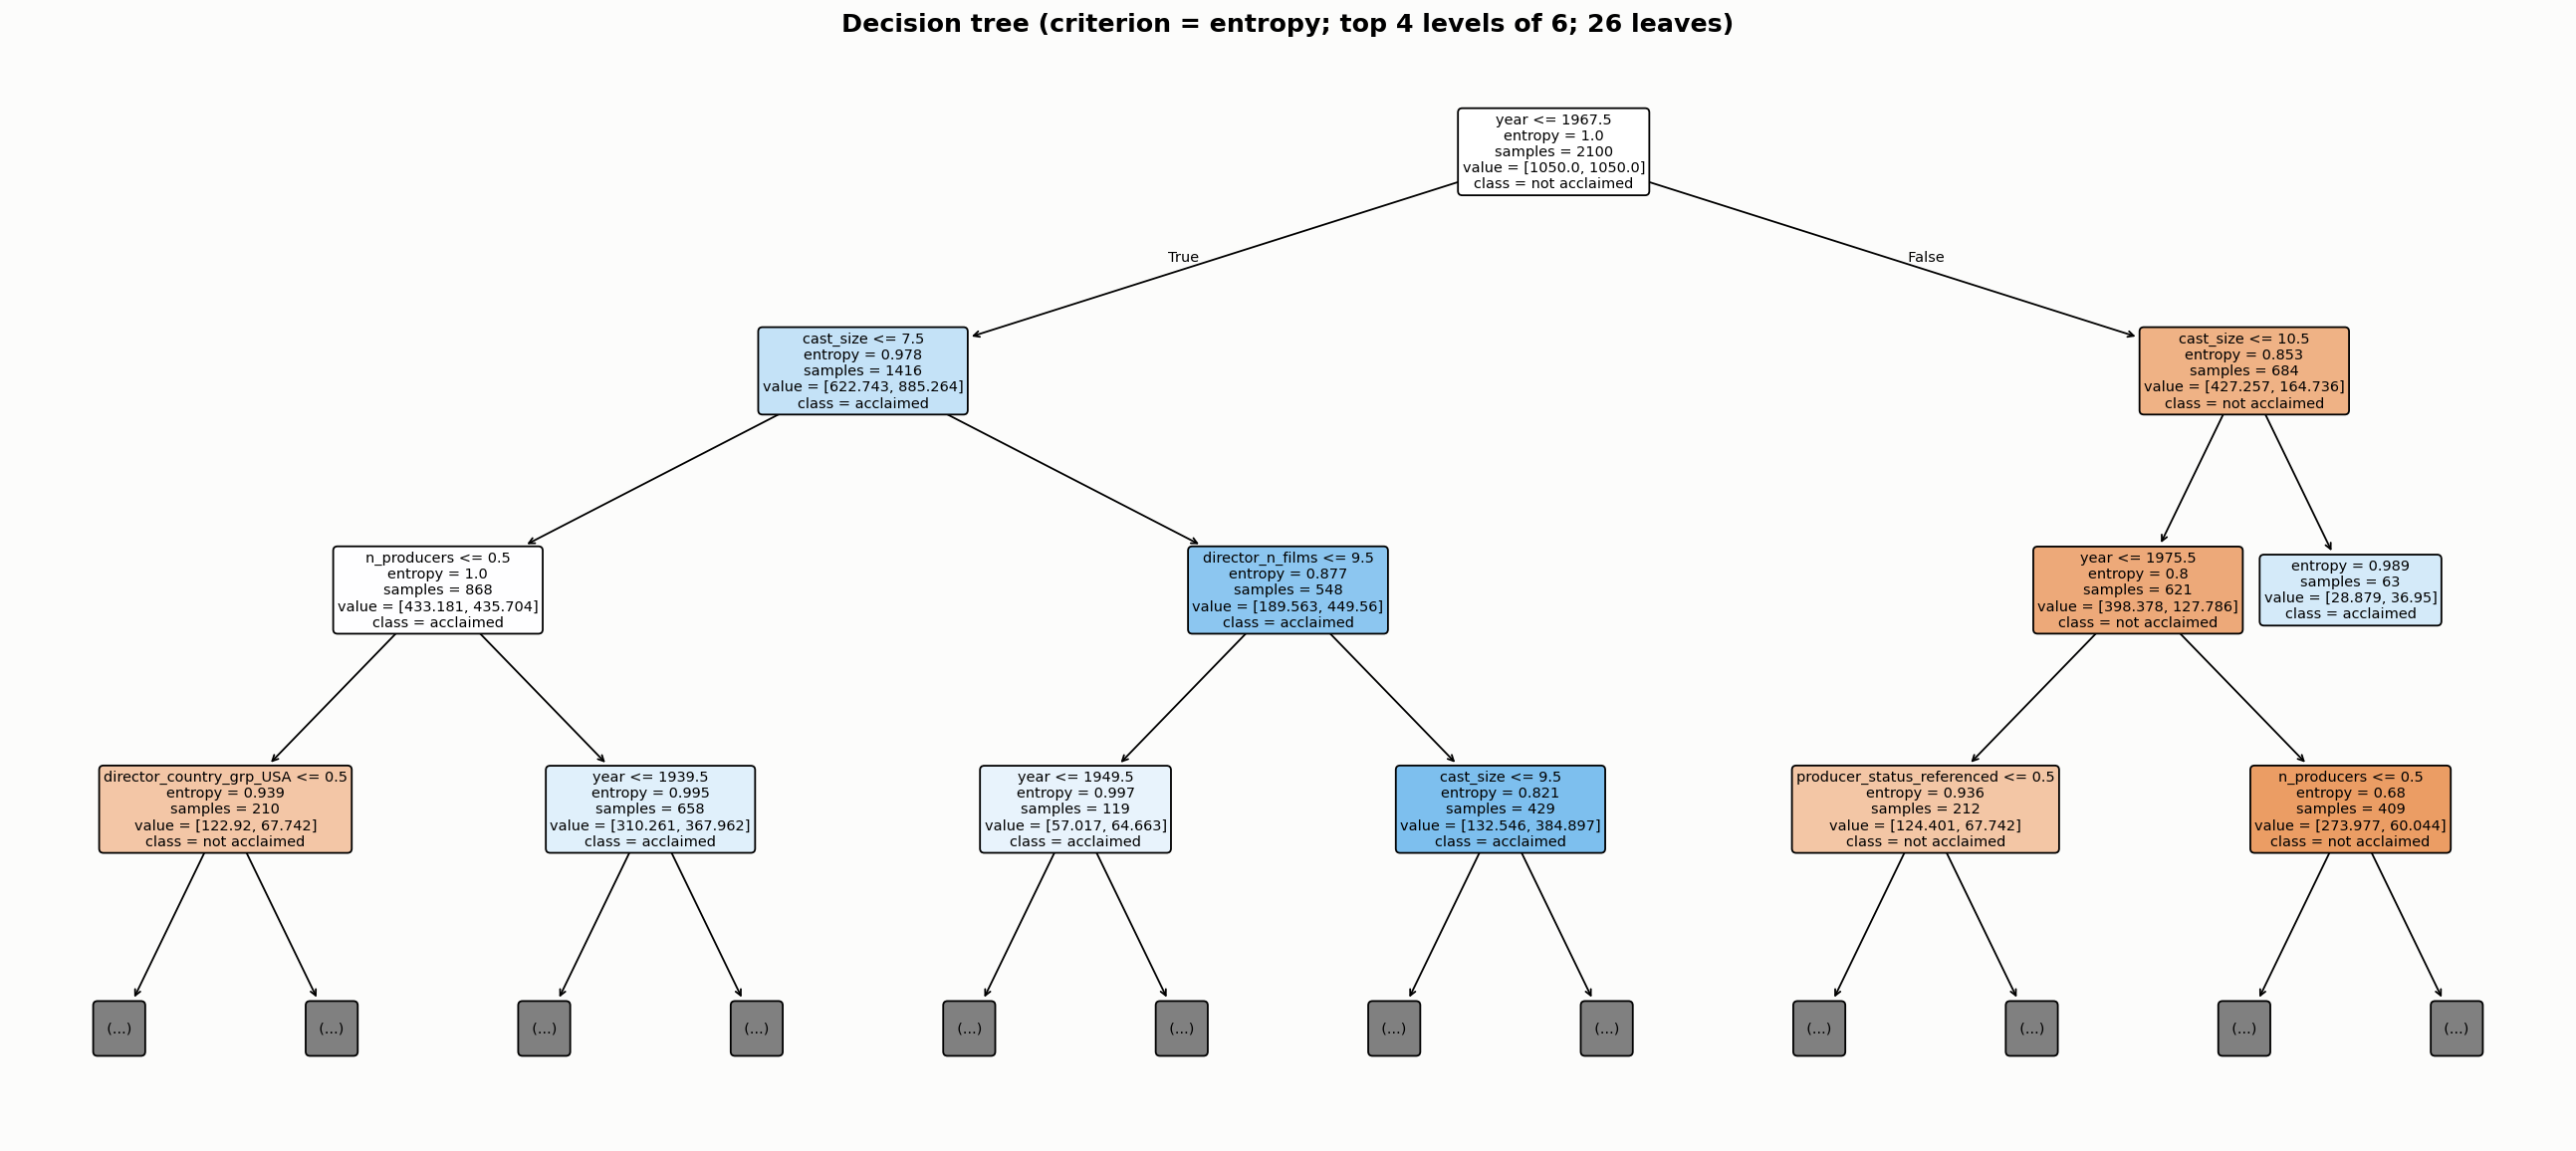

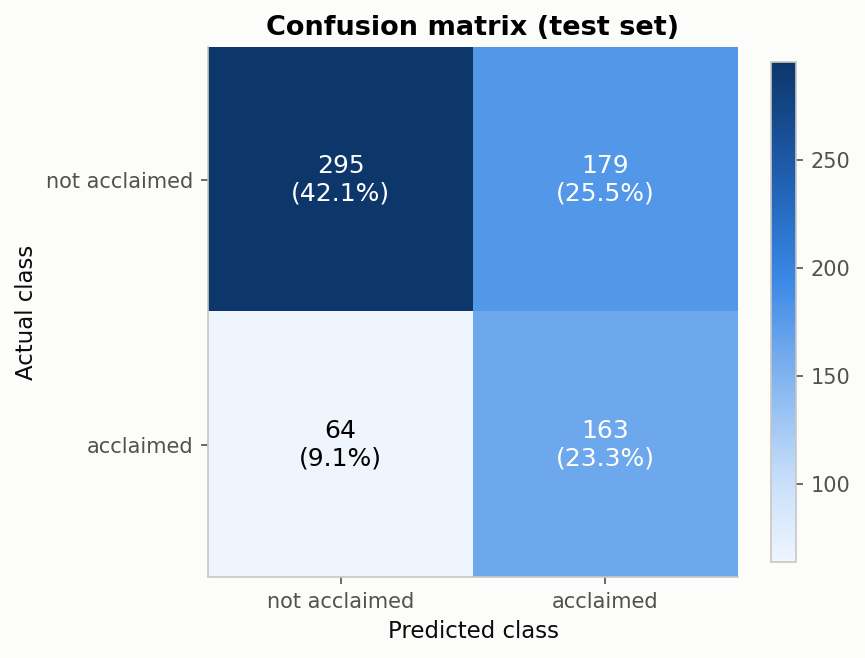

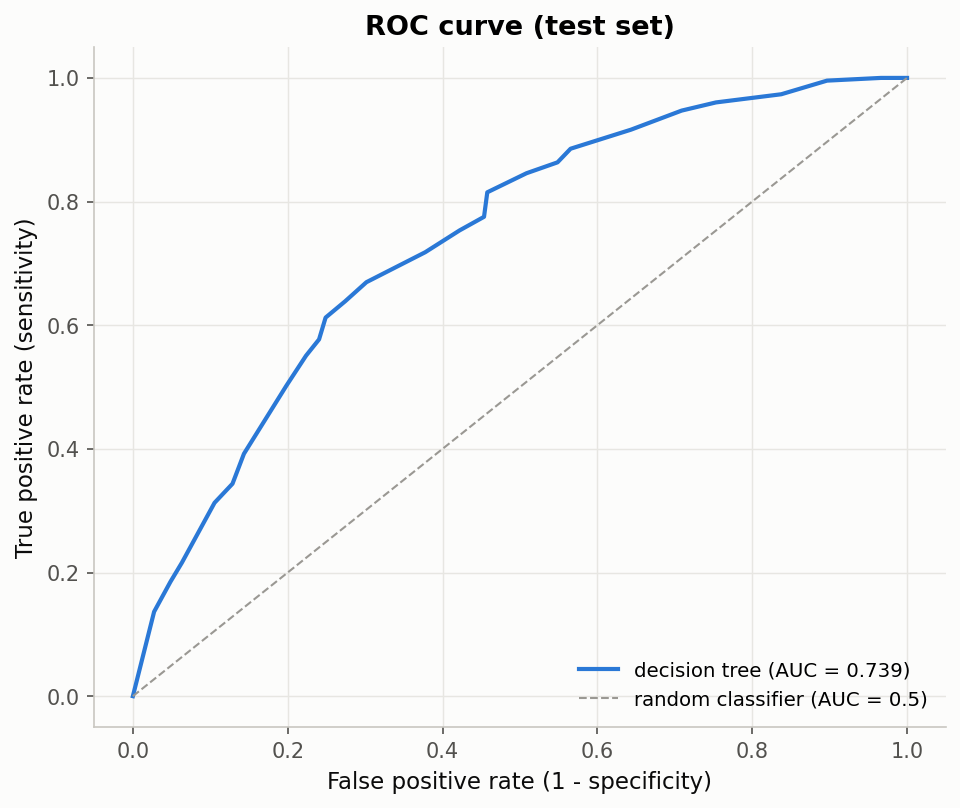

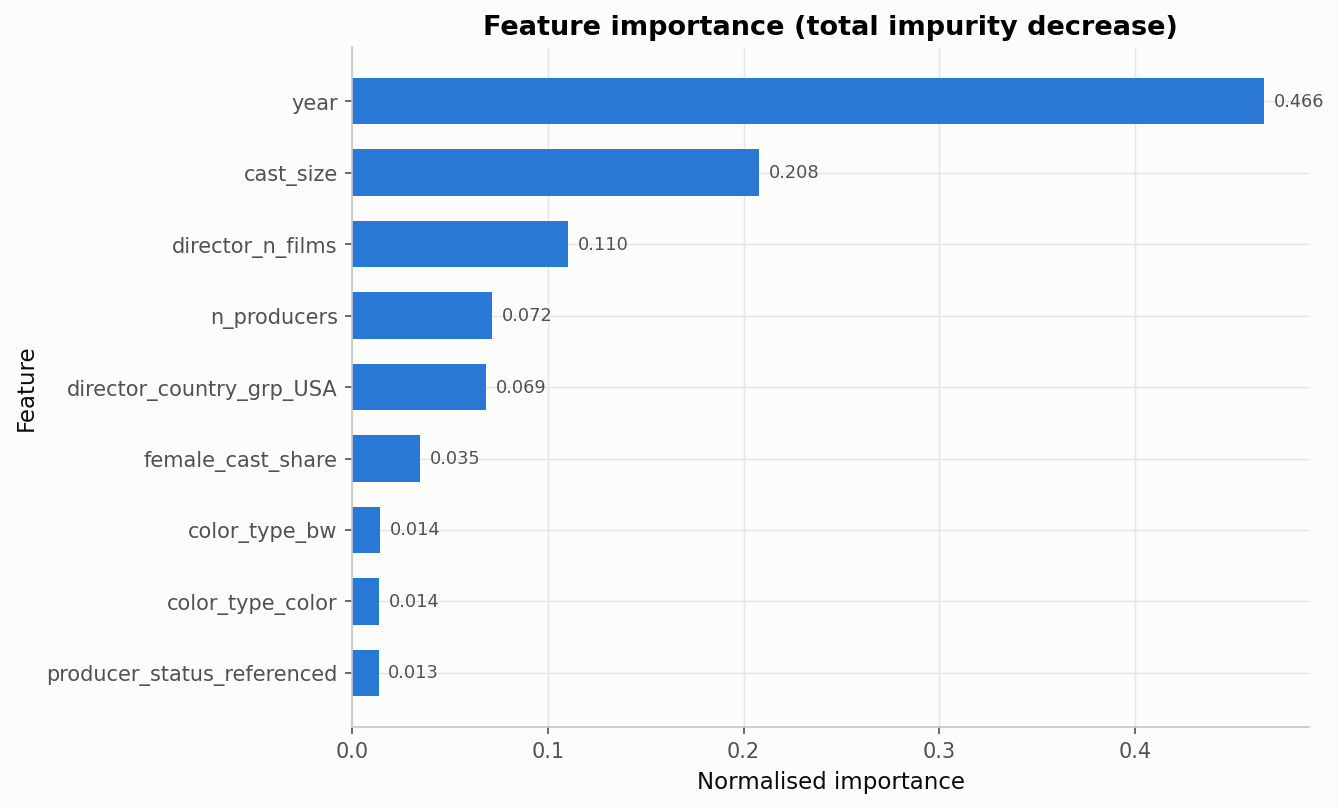

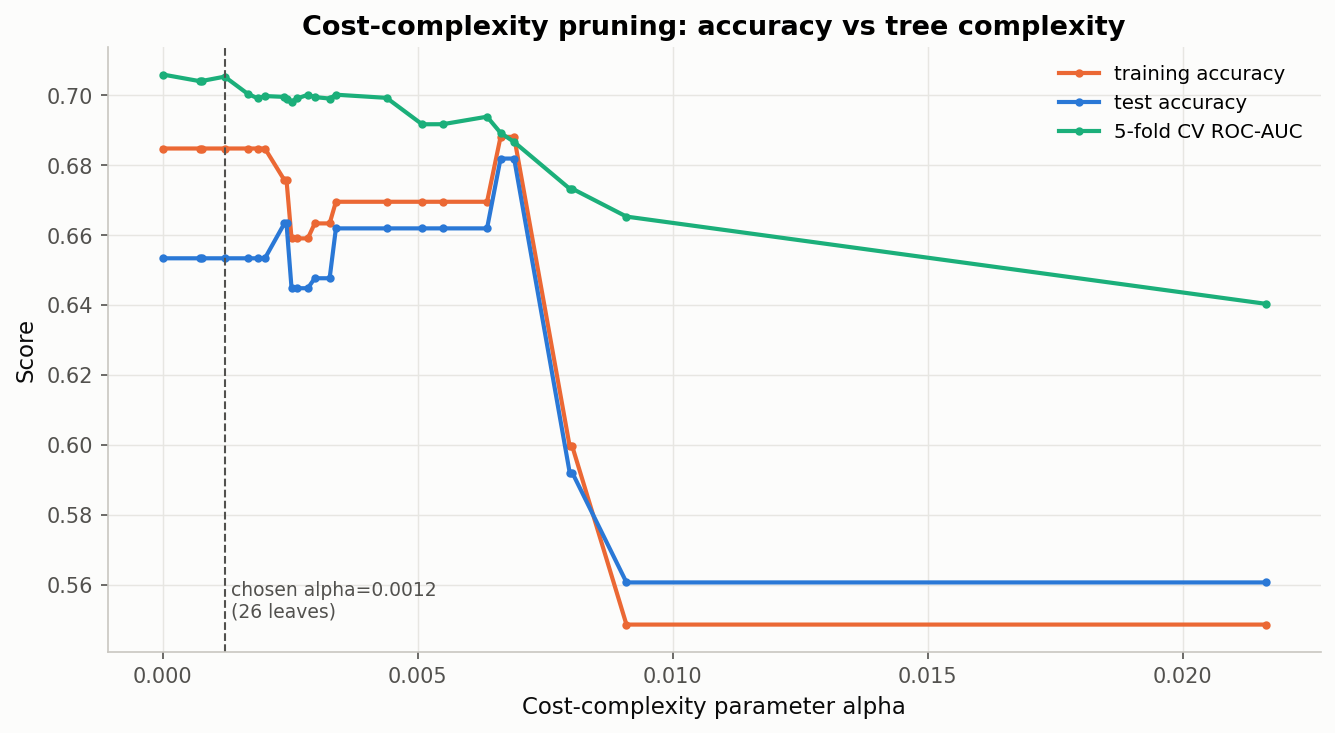

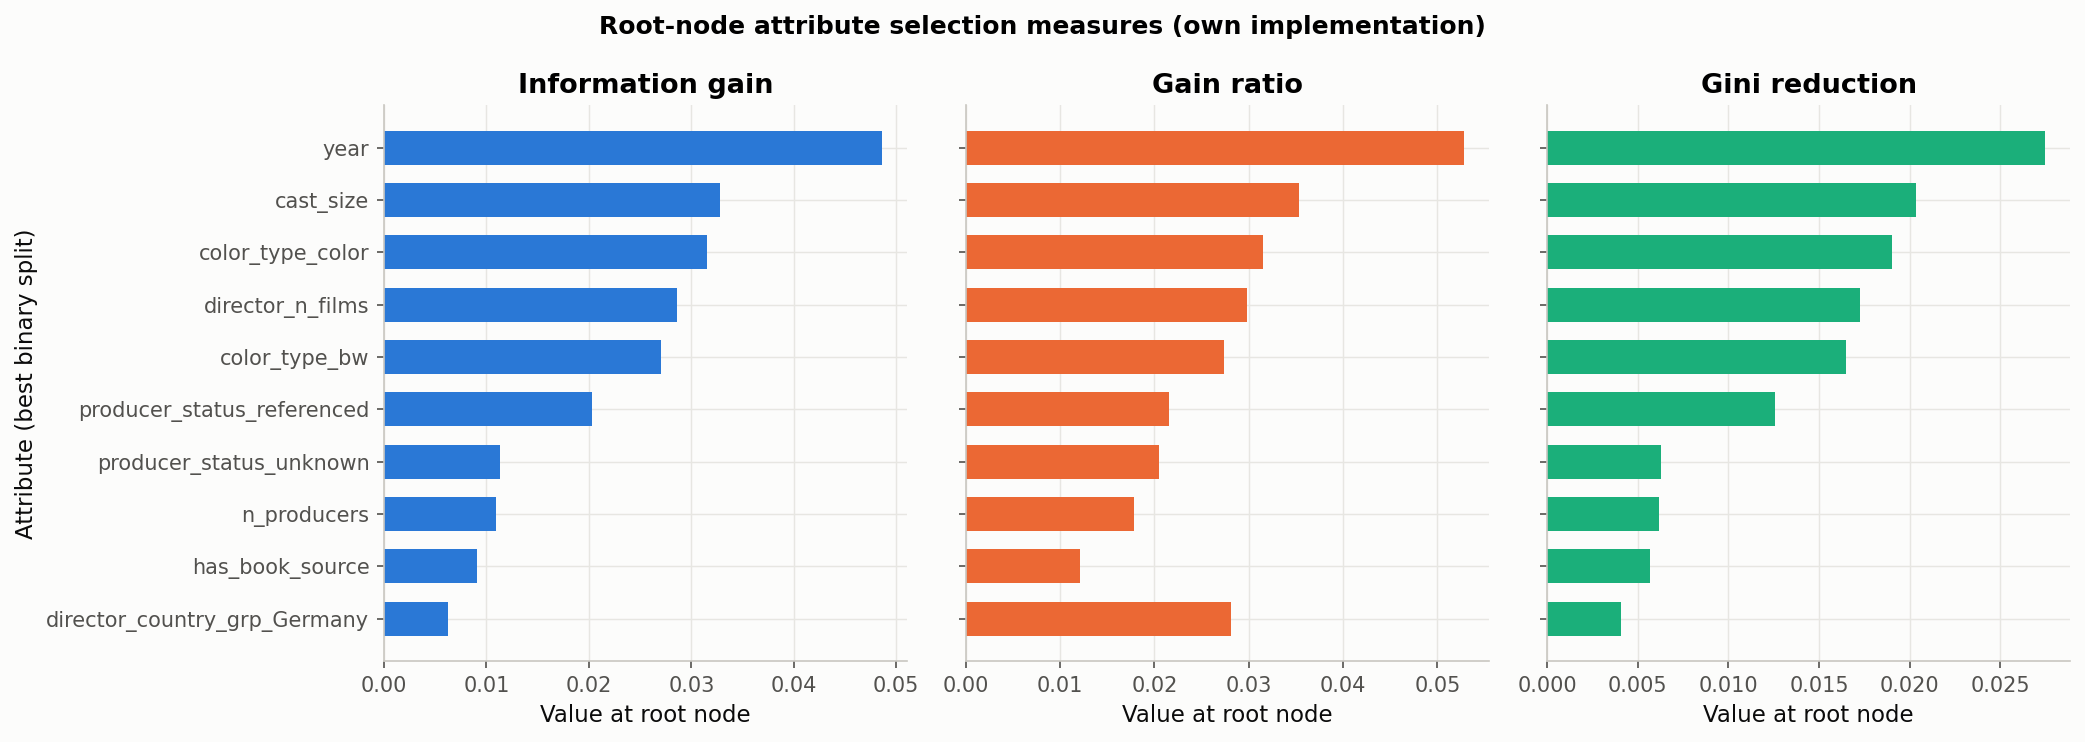

In [6]:
for f in ['23_decision_tree_structure.png','24_decision_tree_confusion_matrix.png','25_decision_tree_roc_curve.png','26_decision_tree_feature_importance.png','27_decision_tree_pruning_curve.png','28_decision_tree_split_criteria.png']: show(f)